0. Описание задачи

В работе будет использован датасет платформы peer-to-peer кредитования Lending Club за 2007–2011 годы.
Он содержит информацию о заемщиках, выданных кредитах, их суммах, процентных ставках и статусах выплат.

Таблица содержит 39 717 записей о кредитных заявках.
Цель: построить модель бинарной классификации, которая по характеристикам заемщика и кредита оценивает вероятность дефолта.

 В качестве целевой переменной используется target, сформированная на основе loan_status. Из анализа исключаются кредиты, исход которых ещё не определён.

1. Чтение данных

In [2]:
import kagglehub
import pandas as pd
import os


path = kagglehub.dataset_download("imsparsh/lending-club-loan-dataset-2007-2011")
file_path = os.path.join(path, "loan.csv")
data_raw = pd.read_csv(file_path, low_memory=False)

data_raw.head()


100%|██████████| 8.39M/8.39M [00:00<00:00, 199MB/s]

Extracting files...


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
0,1077501,1296599,5000,5000,4975.0,36 months,10.65%,162.87,B,B2,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
1,1077430,1314167,2500,2500,2500.0,60 months,15.27%,59.83,C,C4,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
2,1077175,1313524,2400,2400,2400.0,36 months,15.96%,84.33,C,C5,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
3,1076863,1277178,10000,10000,10000.0,36 months,13.49%,339.31,C,C1,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
4,1075358,1311748,3000,3000,3000.0,60 months,12.69%,67.79,B,B5,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN


In [4]:
print("Тип данных:", type(data_raw))

print("\nСписок всех признаков в датасете ")
print(data_raw.columns)

print("\nИнформация о датасете")
data_raw.info()

print("\n Размер датасета")
data_raw.shape

Тип данных: <class 'pandas.core.frame.DataFrame'>

Список всех признаков в датасете 
Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade',
       ...
       'num_tl_90g_dpd_24m', 'num_tl_op_past_12m', 'pct_tl_nvr_dlq',
       'percent_bc_gt_75', 'pub_rec_bankruptcies', 'tax_liens',
       'tot_hi_cred_lim', 'total_bal_ex_mort', 'total_bc_limit',
       'total_il_high_credit_limit'],
      dtype='object', length=111)

Информация о датасете
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39717 entries, 0 to 39716
Columns: 111 entries, id to total_il_high_credit_limit
dtypes: float64(74), int64(13), object(24)
memory usage: 33.6+ MB

 Размер датасета


(39717, 111)

2. Разбиение на выборки

In [31]:
from sklearn.model_selection import train_test_split

df = data_raw.loc[data_raw['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df['target'] = (df['loan_status'] == 'Charged Off').astype(int)

exclude = [
    'loan_status', 'target', 'id', 'member_id', 'url', 'desc',
    'title', 'emp_title', 'last_pymnt_d', 'last_pymnt_amnt',
    'next_pymnt_d', 'last_credit_pull_d', 'out_prncp', 'out_prncp_inv',
    'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
    'total_rec_int', 'total_rec_late_fee', 'recoveries',
    'collection_recovery_fee', 'pymnt_plan', 'initial_list_status',
    'policy_code'
]

X = df.drop(columns=exclude, errors='ignore')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Полный набор признаков:', X.shape)
print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)


Полный набор признаков: (38577, 88)
Обучающая выборка: (30861, 88)
Тестовая выборка: (7716, 88)


3. Визуализация данных и вычисление основных характеристик

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


data = X_train.copy()


data['int_rate'] = pd.to_numeric(
    data['int_rate'].astype(str).str.replace('%', '', regex=False),
    errors='coerce'
)

Основные статистики для суммы кредита:
count    30861.000000
mean     11045.165419
std       7353.306198
min        500.000000
25%       5300.000000
50%       9600.000000
75%      15000.000000
max      35000.000000
Name: loan_amnt, dtype: float64


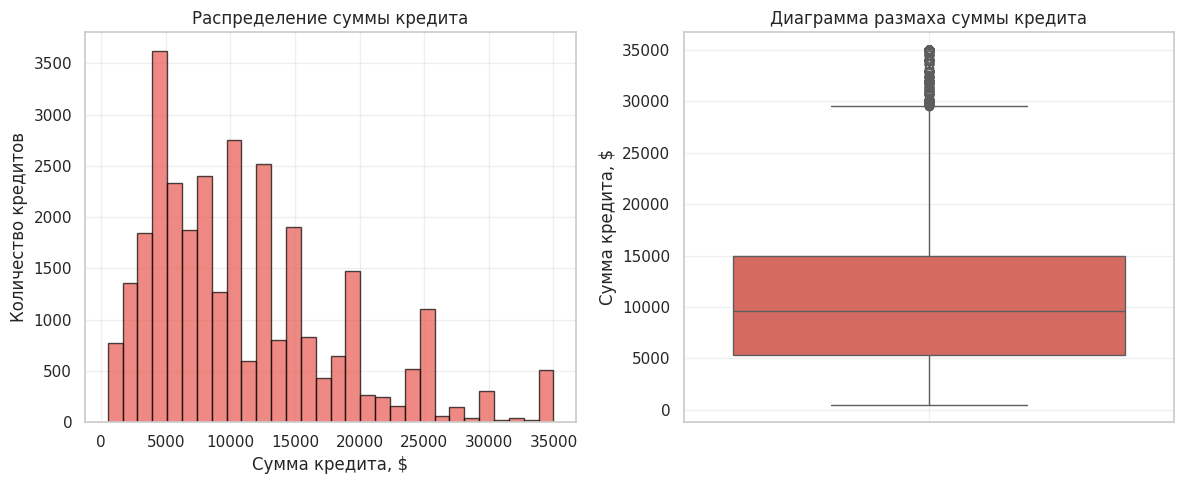

In [33]:
print('Основные статистики для суммы кредита:')
print(data['loan_amnt'].describe())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(data['loan_amnt'].dropna(), bins=30,
         color='#E8594F', alpha=0.7, edgecolor='black')
plt.title('Распределение суммы кредита')
plt.xlabel('Сумма кредита, $')
plt.ylabel('Количество кредитов')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
sns.boxplot(y=data['loan_amnt'], color='#E8594F')
plt.title('Диаграмма размаха суммы кредита')
plt.ylabel('Сумма кредита, $')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

 Интерпретация суммы кредита

Были исследованы суммы кредитов, выданных заёмщикам платформы Lending Club.

Средняя сумма кредита составляет **11045.165419 долларов**, медианная — **9600 долларов**. Минимальная сумма равна **500 долларов**, максимальная — **35000 долларов**.

Стандартное отклонение составляет **7353.306198 долларов**, что характеризует разброс сумм кредитов относительно среднего значения.

По гистограмме можно определить наиболее распространённые суммы кредитов, а диаграмма размаха позволяет оценить наличие потенциальных выбросов.

Основные статистики для годовой процентной ставки:
count    30861.000000
mean        11.946981
std          3.704004
min          5.420000
25%          8.940000
50%         11.780000
75%         14.420000
max         24.400000
Name: int_rate, dtype: float64


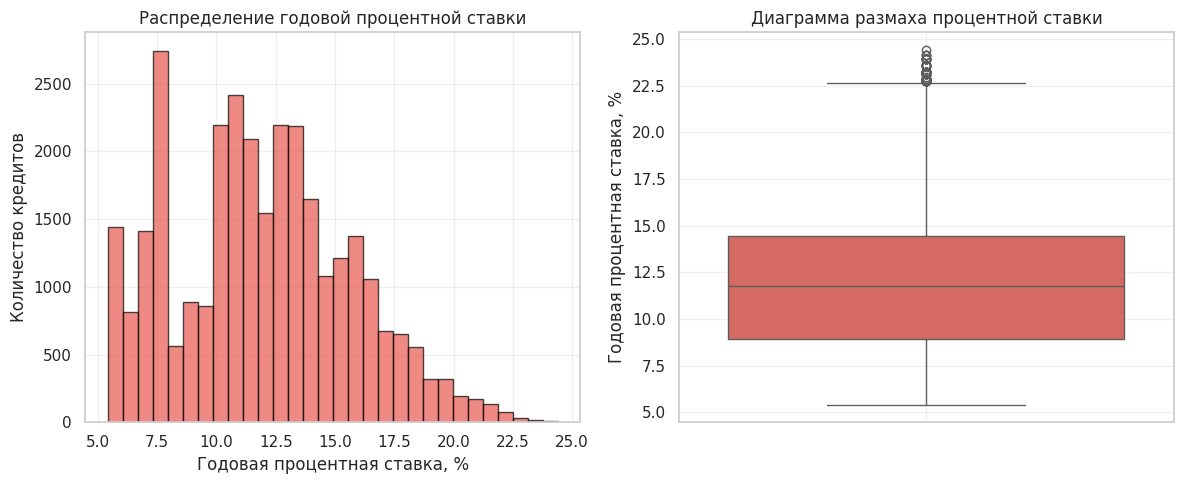

In [26]:
print('Основные статистики для годовой процентной ставки:')
print(data['int_rate'].describe())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(data['int_rate'].dropna(), bins=30,
         color='#E8594F', alpha=0.7, edgecolor='black')
plt.title('Распределение годовой процентной ставки')
plt.xlabel('Годовая процентная ставка, %')
plt.ylabel('Количество кредитов')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
sns.boxplot(y=data['int_rate'], color='#E8594F')
plt.title('Диаграмма размаха процентной ставки')
plt.ylabel('Годовая процентная ставка, %')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

 Интерпретация процентной ставки

Рассматривается годовая процентная ставка по кредиту (`int_rate`), установленная платформой Lending Club.

Средняя годовая процентная ставка составляет **11.946981%**, медианная — **11.78%**. Минимальная ставка равна **5.420%**, максимальная — **24.4%**.

Стандартное отклонение составляет **3.704004 процентного пункта**.

Гистограмма позволяет определить наиболее распространённые процентные ставки, а диаграмма размаха — выявить потенциально необычные значения.

Процентная ставка может быть связана с кредитным риском заёмщика, поэтому представляет интерес для дальнейшего построения модели классификации.

Корреляционная матрица:


,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,total_acc,pub_rec_bankruptcies
loan_amnt,1.00,0.98,0.94,0.30,0.93,0.26,0.06,-0.03,0.01,0.02,0.00,0.18,-0.05,0.31,0.26,-0.03
funded_amnt,0.98,1.00,0.96,0.31,0.96,0.25,0.06,-0.03,0.01,0.02,-0.01,0.18,-0.05,0.31,0.25,-0.03
funded_amnt_inv,0.94,0.96,1.00,0.30,0.91,0.24,0.07,-0.04,-0.00,0.08,0.44,0.16,-0.05,0.29,0.25,-0.04
int_rate,0.30,0.31,0.30,1.00,0.28,0.05,0.11,0.16,0.14,-0.06,0.32,0.01,0.10,0.09,-0.04,0.08
installment,0.93,0.96,0.91,0.28,1.00,0.25,0.05,-0.02,0.01,0.00,-0.06,0.18,-0.04,0.31,0.23,-0.03
annual_inc,0.26,0.25,0.24,0.05,0.25,1.00,-0.12,0.02,0.03,-0.00,-0.03,0.15,-0.02,0.27,0.22,-0.01
dti,0.06,0.06,0.07,0.11,0.05,-0.12,1.00,-0.04,0.00,0.08,0.18,0.29,-0.00,0.22,0.23,0.01
delinq_2yrs,-0.03,-0.03,-0.04,0.16,-0.02,0.02,-0.04,1.00,0.01,-0.57,-0.04,0.01,0.01,-0.06,0.06,0.01
inq_last_6mths,0.01,0.01,-0.00,0.14,0.01,0.03,0.00,0.01,1.00,-0.00,-0.03,0.09,0.02,-0.02,0.11,0.01
mths_since_last_delinq,0.02,0.02,0.08,-0.06,0.00,-0.00,0.08,-0.57,-0.00,1.00,0.48,0.03,0.06,0.02,0.02,0.02


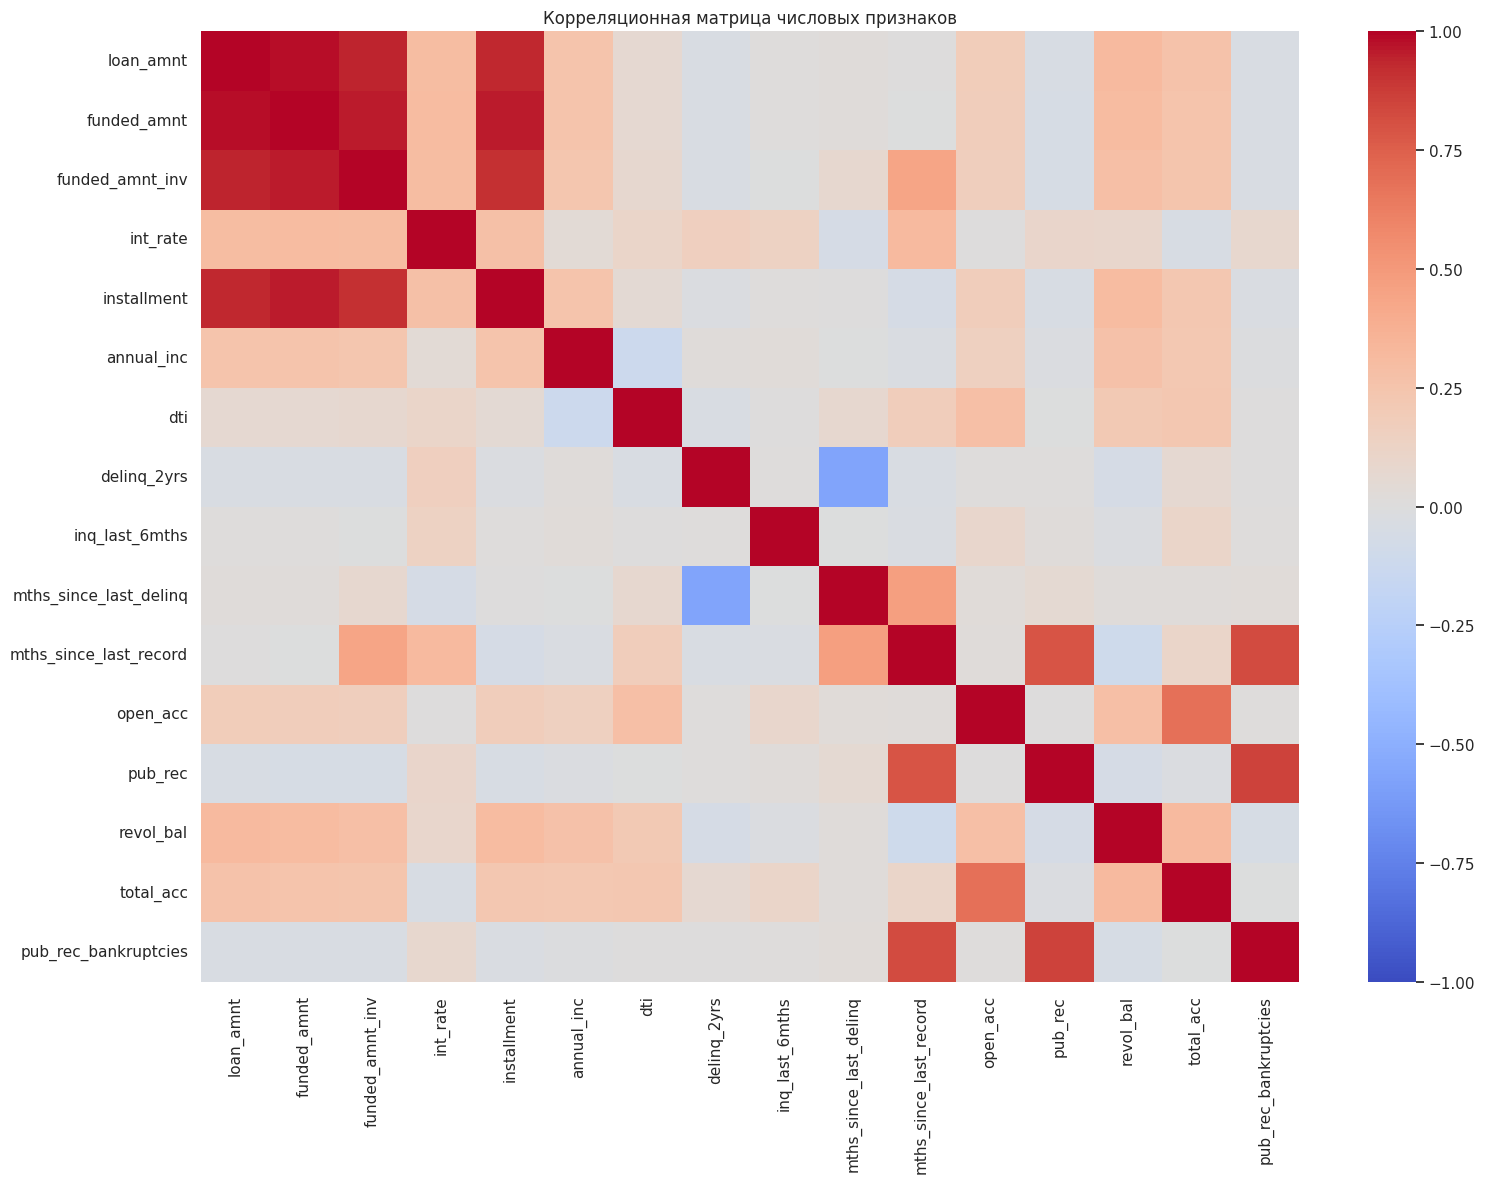

In [30]:

numeric_data = data.select_dtypes(include='number')


numeric_data = numeric_data.loc[
    :, numeric_data.nunique(dropna=True) > 1
]


corr_matrix = numeric_data.corr()

print('Корреляционная матрица:')
display(corr_matrix.round(2))


plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

In [29]:

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

corr_pairs = upper.stack().reset_index()
corr_pairs.columns = ['Признак 1', 'Признак 2', 'Корреляция']

corr_pairs['Модуль корреляции'] = (
    corr_pairs['Корреляция'].abs()
)

corr_pairs = corr_pairs.sort_values(
    'Модуль корреляции',
    ascending=False
)

print('Наиболее сильные корреляции:')
display(corr_pairs.head(10).round(3))

Наиболее сильные корреляции:


,Признак 1,Признак 2,Корреляция,Модуль корреляции
0,loan_amnt,funded_amnt,0.982,0.982
17,funded_amnt,installment,0.958,0.958
15,funded_amnt,funded_amnt_inv,0.957,0.957
1,loan_amnt,funded_amnt_inv,0.939,0.939
3,loan_amnt,installment,0.933,0.933
30,funded_amnt_inv,installment,0.906,0.906
116,pub_rec,pub_rec_bankruptcies,0.854,0.854
109,mths_since_last_record,pub_rec_bankruptcies,0.825,0.825
106,mths_since_last_record,pub_rec,0.792,0.792
112,open_acc,total_acc,0.687,0.687



Интерпретация корреляционной матрицы

Для анализа линейных взаимосвязей между числовыми признаками была построена корреляционная матрица Пирсона.

Наиболее сильная положительная корреляция наблюдается между признаками **loan_amnt** (запрашиваемая сумма кредита) и **funded_amnt** (фактически профинансированная сумма кредита). Коэффициент корреляции составляет **0.982**. Это свидетельствует о сильной положительной линейной связи: чем больше запрашиваемая сумма кредита, тем больше, как правило, сумма его финансирования.

Также высокая положительная корреляция наблюдается между **funded_amnt** и **installment** (ежемесячный платёж) — **0.958**, а также между **funded_amnt** и **funded_amnt_inv** (сумма, профинансированная инвесторами) — **0.957**.

Высокая корреляция между этими признаками указывает на частичное дублирование информации. При дальнейшем построении модели классификации можно рассмотреть исключение некоторых сильно коррелирующих признаков, чтобы уменьшить избыточность данных.

4. Анализ выбросов

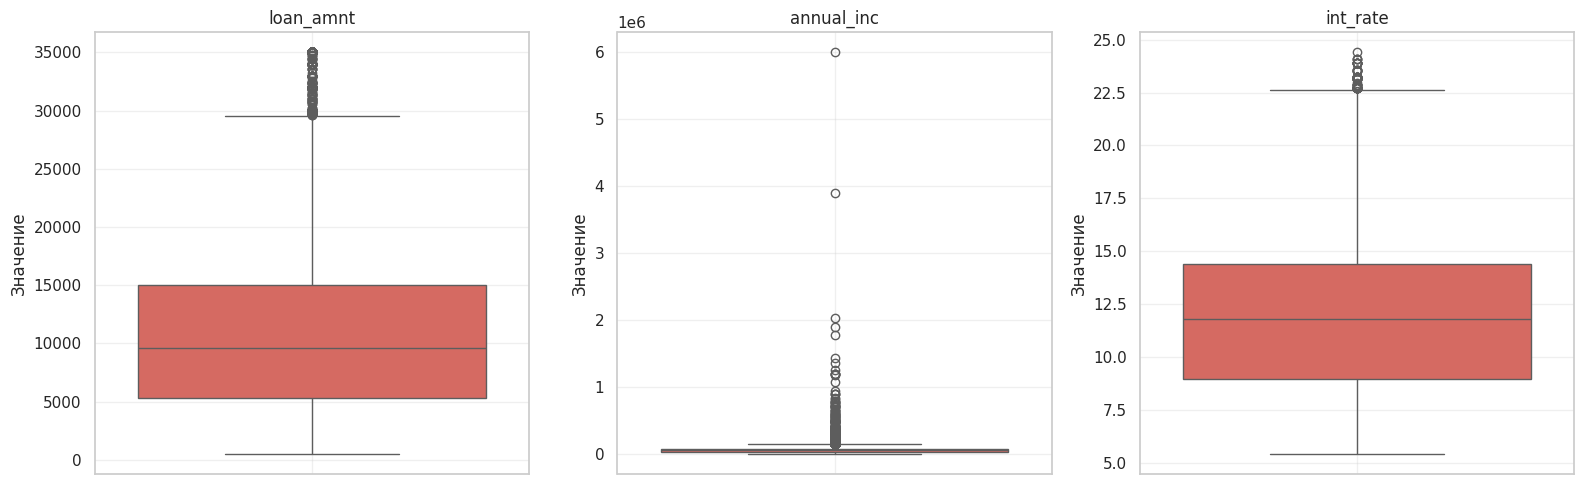

In [35]:

outlier_data = X_train.copy()

outlier_data['int_rate'] = pd.to_numeric(
    outlier_data['int_rate']
    .astype(str)
    .str.replace('%', '', regex=False),
    errors='coerce'
)

features = ['loan_amnt', 'annual_inc', 'int_rate']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(features):
    sns.boxplot(
        y=outlier_data[feature],
        ax=axes[i],
        color='#E8594F'
    )

    axes[i].set_title(feature)
    axes[i].set_ylabel('Значение')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
results = []

for feature in features:
    s = outlier_data[feature].dropna()

    Q1 = s.quantile(0.25)
    Q3 = s.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = s[(s < lower) | (s > upper)]

    results.append({
        'Признак': feature,
        'Нижняя граница': round(lower, 2),
        'Верхняя граница': round(upper, 2),
        'Количество выбросов': len(outliers),
        'Доля выбросов, %': round(
            len(outliers) / len(s) * 100, 2
        )
    })

outliers_table = pd.DataFrame(results)

display(outliers_table)

,Признак,Нижняя граница,Верхняя граница,Количество выбросов,"Доля выбросов, %"
0,loan_amnt,-9250.00,29550.00,880,2.85
1,annual_inc,-23000.00,145000.00,1400,4.54
2,int_rate,0.72,22.64,57,0.18


Решение об обработке выбросов

На данном этапе принято решение **не удалять потенциальные выбросы автоматически**.

Это связано с тем, что экстремальные значения могут соответствовать реальным заёмщикам и кредитам. Их удаление может привести к потере полезной информации.


5. Обработка пропущенных значений

Проверим наличие пропущенных значений в обучающей и тестовой выборках.

Для числовых признаков будем использовать заполнение медианой, поскольку она менее чувствительна к экстремальным значениям, чем среднее арифметическое.

Для категориальных признаков пропуски заполним отдельным значением Unknown.

Параметры заполнения числовых признаков будут вычисляться только по обучающей выборке, чтобы избежать утечки информации из тестовой выборки.

In [37]:
import pandas as pd
import numpy as np

print('Пропуски в обучающей выборке:')
display(X_train.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False))

print('Пропуски в тестовой выборке:')
display(X_test.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False))

Пропуски в обучающей выборке:


,0
mths_since_last_major_derog,30861
tot_cur_bal,30861
tot_coll_amt,30861
verification_status_joint,30861
dti_joint,30861
...,...
pub_rec_bankruptcies,557
chargeoff_within_12_mths,43
collections_12_mths_ex_med,43
revol_util,40


Пропуски в тестовой выборке:


,0
mths_since_last_major_derog,7716
tot_cur_bal,7716
tot_coll_amt,7716
verification_status_joint,7716
dti_joint,7716
...,...
pub_rec_bankruptcies,140
chargeoff_within_12_mths,13
collections_12_mths_ex_med,13
revol_util,10


In [38]:
from sklearn.impute import SimpleImputer

X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

for df in [X_train_clean, X_test_clean]:
    if 'int_rate' in df.columns:
        df['int_rate'] = pd.to_numeric(
            df['int_rate'].astype('string')
            .str.replace('%', '', regex=False)
            .str.strip(),
            errors='coerce'
        )


drop_cols = X_train_clean.columns[
    X_train_clean.isna().all() |
    (X_train_clean.nunique(dropna=True) <= 1)
]

X_train_clean = X_train_clean.drop(columns=drop_cols)
X_test_clean = X_test_clean.drop(columns=drop_cols)


numeric_cols = X_train_clean.select_dtypes(
    include='number'
).columns.tolist()

categorical_cols = [
    col for col in X_train_clean.columns
    if col not in numeric_cols
]


imputer = SimpleImputer(strategy='median')

X_train_clean[numeric_cols] = imputer.fit_transform(
    X_train_clean[numeric_cols]
)

X_test_clean[numeric_cols] = imputer.transform(
    X_test_clean[numeric_cols]
)


for col in categorical_cols:
    X_train_clean[col] = X_train_clean[col].fillna('Unknown')
    X_test_clean[col] = X_test_clean[col].fillna('Unknown')

print('Пропуски после обработки:')
print('Обучающая:', X_train_clean.isna().sum().sum())
print('Тестовая:', X_test_clean.isna().sum().sum())

Пропуски после обработки:
Обучающая: 0
Тестовая: 0


6. Обработка категориальных признаков

In [39]:
categorical_cols = X_train_clean.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

print('Количество категориальных признаков:', len(categorical_cols))
print('Категориальные признаки:')
print(categorical_cols)


display(
    X_train_clean[categorical_cols]
    .nunique()
    .sort_values(ascending=False)
)

Количество категориальных признаков: 12
Категориальные признаки:
['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'issue_d', 'purpose', 'zip_code', 'addr_state', 'earliest_cr_line', 'revol_util']


,0
revol_util,1073
zip_code,812
earliest_cr_line,510
issue_d,54
addr_state,50
sub_grade,35
purpose,14
emp_length,12
grade,7
home_ownership,5


In [40]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown='ignore',
    min_frequency=0.01,
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(
    X_train_clean[categorical_cols]
)

X_test_encoded = encoder.transform(
    X_test_clean[categorical_cols]
)

encoded_columns = encoder.get_feature_names_out(categorical_cols)

train_dummies = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train_clean.index
)

test_dummies = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test_clean.index
)

display(train_dummies.head())

,term_ 36 months,term_ 60 months,grade_A,grade_B,grade_C,grade_D,grade_E,grade_F,grade_infrequent_sklearn,sub_grade_A1,...,addr_state_PA,addr_state_SC,addr_state_TX,addr_state_VA,addr_state_WA,addr_state_WI,addr_state_infrequent_sklearn,earliest_cr_line_infrequent_sklearn,revol_util_0%,revol_util_infrequent_sklearn
5892,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
17046,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
20835,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
8102,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
9900,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


In [41]:
numeric_cols = X_train_clean.select_dtypes(
    include='number'
).columns.tolist()

X_train_processed = pd.concat(
    [X_train_clean[numeric_cols], train_dummies],
    axis=1
)

X_test_processed = pd.concat(
    [X_test_clean[numeric_cols], test_dummies],
    axis=1
)

print('Размер обучающей выборки:', X_train_processed.shape)
print('Размер тестовой выборки:', X_test_processed.shape)

display(X_train_processed.head())

Размер обучающей выборки: (30861, 149)
Размер тестовой выборки: (7716, 149)


,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,inq_last_6mths,mths_since_last_delinq,...,addr_state_PA,addr_state_SC,addr_state_TX,addr_state_VA,addr_state_WA,addr_state_WI,addr_state_infrequent_sklearn,earliest_cr_line_infrequent_sklearn,revol_util_0%,revol_util_infrequent_sklearn
5892,12000.0,12000.0,11925.0,19.42,314.07,207000.0,16.50,0.0,0.0,34.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
17046,19200.0,19200.0,19175.0,11.11,418.51,87500.0,13.39,0.0,1.0,45.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
20835,9600.0,9600.0,9550.0,5.79,291.14,39000.0,7.14,0.0,0.0,34.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
8102,18000.0,18000.0,18000.0,11.49,593.49,90000.0,19.03,0.0,2.0,34.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
9900,6000.0,6000.0,6000.0,9.99,193.58,53000.0,12.88,0.0,0.0,48.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


 Интерпретация

В датасете Lending Club присутствуют категориальные признаки, описывающие характеристики заёмщика и условия кредитования.

Для их преобразования был использован метод One-Hot Encoding, который заменяет категориальные значения набором бинарных признаков.

Редкие категории были объединены, чтобы избежать чрезмерного увеличения размерности данных.

В результате все категориальные признаки были преобразованы в числовой формат, необходимый для применения метода k ближайших соседей.

7. Нормализация данных

In [44]:
from sklearn.preprocessing import StandardScaler


X_train_scaled = X_train_processed.copy()
X_test_scaled = X_test_processed.copy()

scaler = StandardScaler()


X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_processed[numeric_cols]
)

X_test_scaled[numeric_cols] = scaler.transform(
    X_test_processed[numeric_cols]
)
print("Средние значения после стандартизации:")
display(X_train_scaled[numeric_cols].mean().round(3))

print("\nСтандартные отклонения после стандартизации:")
display(X_train_scaled[numeric_cols].std(ddof=0).round(3))

Средние значения после стандартизации:


,0
loan_amnt,0.0
funded_amnt,-0.0
funded_amnt_inv,-0.0
int_rate,0.0
installment,-0.0
annual_inc,-0.0
dti,0.0
delinq_2yrs,-0.0
inq_last_6mths,-0.0
mths_since_last_delinq,-0.0



Стандартные отклонения после стандартизации:


,0
loan_amnt,1.0
funded_amnt,1.0
funded_amnt_inv,1.0
int_rate,1.0
installment,1.0
annual_inc,1.0
dti,1.0
delinq_2yrs,1.0
inq_last_6mths,1.0
mths_since_last_delinq,1.0


 8-9. Обучение классификатора k ближайших соседей и ошибки

Для решения задачи бинарной классификации был выбран метод k ближайших соседей.

Выбор метода обусловлен его простотой, интерпретируемостью и возможностью учитывать сходство между кредитами по характеристикам заёмщиков и условиям кредитования.

В качестве начального значения количества соседей выберем k = 5. Оптимальное значение будет определено в следующем пункте.

In [78]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier


X_train_model = X_train.copy()
X_test_model = X_test.copy()

empty_cols = X_train_model.columns[
    X_train_model.isna().all()
]

X_train_model = X_train_model.drop(columns=empty_cols)
X_test_model = X_test_model.drop(columns=empty_cols)

print("Удалено полностью пустых столбцов:", len(empty_cols))

for df in [X_train_model, X_test_model]:
    if 'int_rate' in df.columns:
        df['int_rate'] = pd.to_numeric(
            df['int_rate'].astype(str).str.replace('%', '', regex=False),
            errors='coerce'
        )


numeric_features = X_train_model.select_dtypes(
    include='number'
).columns.tolist()

categorical_features = X_train_model.select_dtypes(
    exclude='number'
).columns.tolist()


numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=0.01
    ))
])


preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])


knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier())
])

print("Pipeline успешно создан")

Удалено полностью пустых столбцов: 54
Pipeline успешно создан


In [79]:
from sklearn.base import clone

knn = clone(knn_pipeline)
knn.set_params(knn__n_neighbors=5)

knn.fit(X_train_model, y_train)

print("Классификатор KNN успешно обучен")


Классификатор KNN успешно обучен


In [80]:
y_train_pred = knn.predict(X_train_model)
y_test_pred = knn.predict(X_test_model)

print("Первые 10 предсказаний:")
print(y_test_pred[:10])

print("\nПервые 10 реальных значений:")
print(y_test.iloc[:10].values)

Первые 10 предсказаний:
[0 0 0 0 0 0 0 0 0 0]

Первые 10 реальных значений:
[1 0 0 0 0 0 0 1 0 0]


Интерпретация

На подготовленной обучающей выборке был обучен классификатор k ближайших соседей с параметром k = 5.

После обучения модель использовалась для прогнозирования статуса кредитов на обучающей и тестовой выборках.

Полученные предсказания относятся к двум классам: 0 — полностью погашенный кредит, 1 — кредит, списанный из-за проблем с погашением.



Ошибка обучения: 0.1316
Ошибка тестирования: 0.1634
Precision: 0.2622
Recall: 0.0667
F1-score: 0.1063


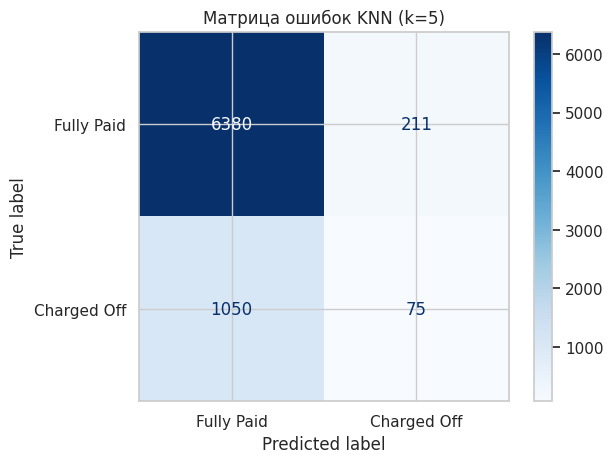

In [81]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Ошибка обучения:", round(1 - accuracy_score(y_train, y_train_pred), 4))
print("Ошибка тестирования:", round(1 - accuracy_score(y_test, y_test_pred), 4))

print("Precision:", round(precision_score(y_test, y_test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_test_pred, zero_division=0), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=["Fully Paid", "Charged Off"],
    cmap="Blues"
)
plt.title("Матрица ошибок KNN (k=5)")
plt.show()

In [82]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11, 15, 21, 31]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train_model, y_train)

best_k = grid_search.best_params_["knn__n_neighbors"]

print("Оптимальное k:", best_k)
print("Лучший F1-score:", round(grid_search.best_score_, 4))

Fitting 3 folds for each of 7 candidates, totalling 21 fits
Оптимальное k: 3
Лучший F1-score: 0.1492


In [83]:
import pandas as pd

best_knn = grid_search.best_estimator_
best_k = grid_search.best_params_["knn__n_neighbors"]

comparison_rows = []

for name, model in [
    ("KNN, k=5", knn),
    (f"KNN, k={best_k}", best_knn)
]:
    train_pred = model.predict(X_train_model)
    test_pred = model.predict(X_test_model)

    comparison_rows.append({
        "Модель": name,
        "Ошибка обучения": 1 - accuracy_score(y_train, train_pred),
        "Ошибка тестирования": 1 - accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F1-score": f1_score(y_test, test_pred, zero_division=0)
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

,Модель,Ошибка обучения,Ошибка тестирования,Precision,Recall,F1-score
0,"KNN, k=5",0.1316,0.1634,0.2622,0.0667,0.1063
1,"KNN, k=3",0.1140,0.1804,0.2247,0.0969,0.1354


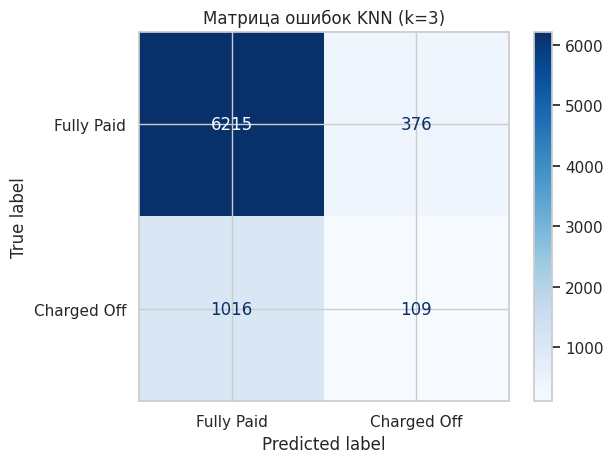

In [84]:
y_test_best = best_knn.predict(X_test_model)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_best,
    display_labels=["Fully Paid", "Charged Off"],
    cmap="Blues"
)

plt.title(f"Матрица ошибок KNN (k={best_k})")
plt.show()

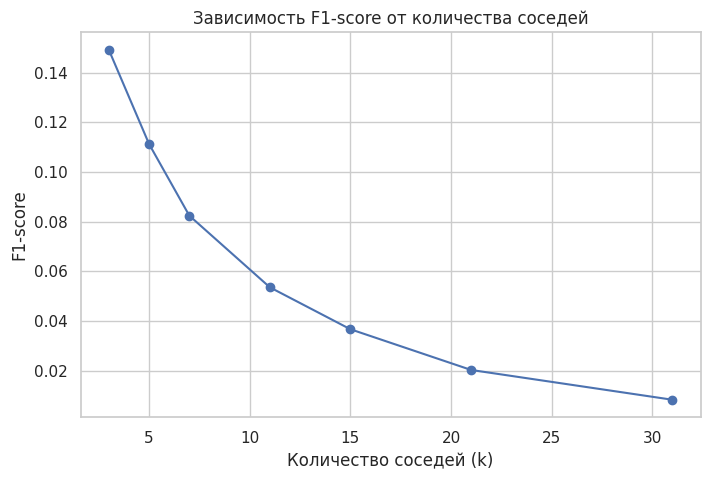

In [85]:
results = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(8, 5))

plt.plot(
    results['param_knn__n_neighbors'],
    results['mean_test_score'],
    marker='o'
)

plt.xlabel('Количество соседей (k)')
plt.ylabel('F1-score')
plt.title('Зависимость F1-score от количества соседей')
plt.grid(True)
plt.show()

 Интерпретация результатов

В ходе работы были рассчитаны ошибки классификации на обучающей и тестовой выборках, построены матрицы ошибок и проведён подбор оптимального количества соседей методом кросс-валидации.

Оптимальным оказалось значение **k = 3**. По сравнению с исходной моделью (k = 5) F1-score увеличился с 0,1063 до 0,1354, однако ошибка тестирования выросла с 0,1634 до 0,1804.

Recall увеличился с 0,0667 до 0,0969, то есть модель стала обнаруживать больше проблемных кредитов. Однако качество их распознавания остаётся низким, что может быть связано с дисбалансом классов.

Таким образом, подбор гиперпараметра улучшил F1-score, но не все показатели качества классификации.

13 выводы

В ходе работы был проведён анализ и предобработка данных Lending Club, обучен классификатор KNN и подобрано оптимальное количество соседей. Модель показала ограниченное качество распознавания проблемных кредитов, поэтому для улучшения результатов рекомендуется рассмотреть другие алгоритмы классификации.